# 환각의 구조적 원인

**이 노트북에서 할 일**

1. 지어낸 연구소와 제품을 묻는 질문 두 개로 답을 받고, 질문 낱말과 답의 첫머리를 바꿔 봅니다.
2. 답에서 숫자를 찾는 함수로 근거 없는 숫자와 보류 문장을 판정하고, 그 판정이 놓치는 것을 봅니다.
3. 근거 문서와 보류 지시를 넣어 같은 질문을 다시 묻고, 결과를 어디까지 말할 수 있는지 판단합니다.

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 작은 언어 모델을 실행합니다.
그래서 비용은 들지 않습니다. 모델이 답을 만드는 계산은 모두 12번 합니다.

실행 시간은 1분 안팎입니다. 모델 파일은 03~06절과 같은 약 1GB(954MiB)이고, 캐시에 없으면 Hugging Face 사이트에서 내려받습니다.
노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.2GB였습니다.

**기준 버전** — 실습 폴더에 고정한 transformers 4.56.2와 torch 2.8.0을 씁니다.
모델은 `Qwen/Qwen2.5-0.5B-Instruct`이고, 판 번호(revision)를 `7ae557604adf67be50417f59c2c2f167def9a775`로 고정해 받습니다.

교재 출력은 Linux(aarch64)의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다. 다른 버전, GPU, Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

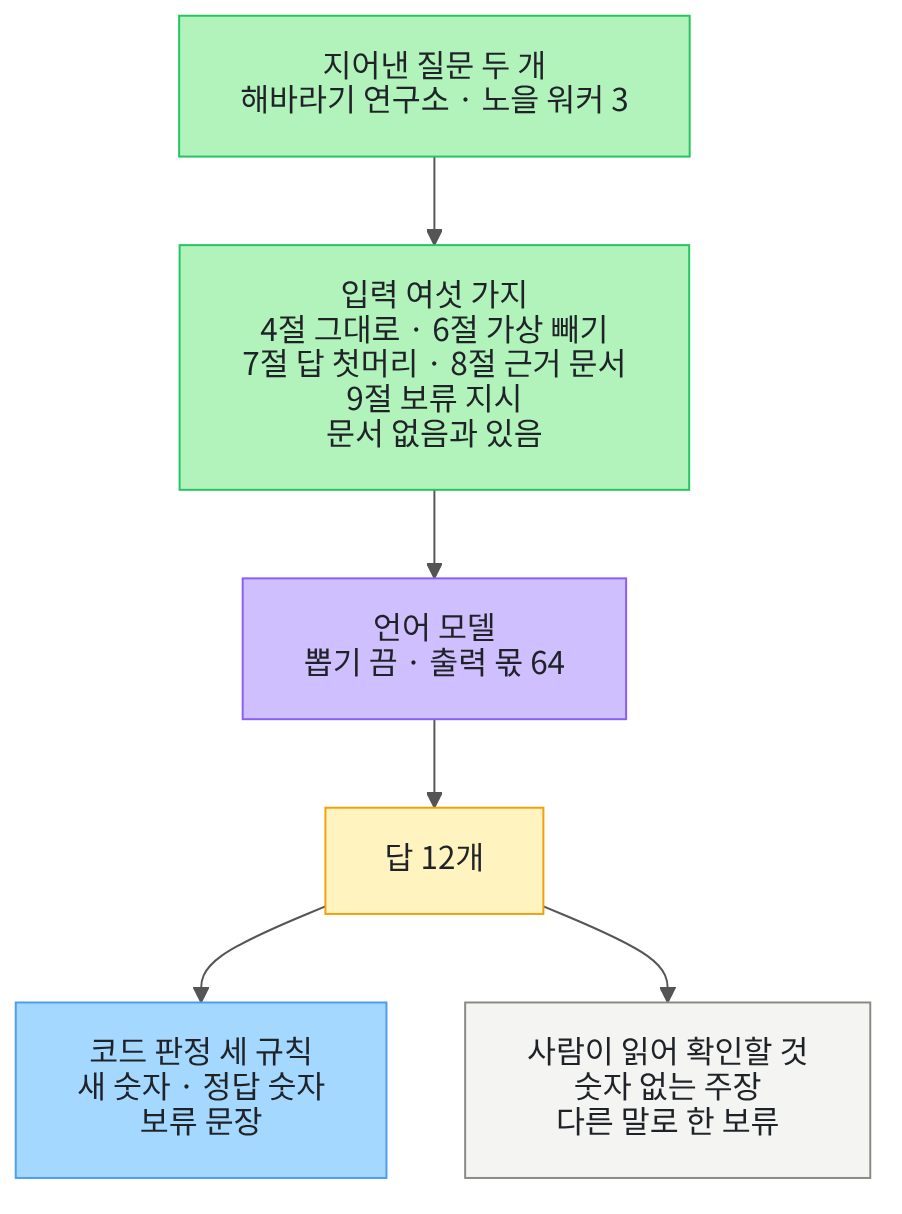

위에서 아래로 읽습니다. 초록 상자는 노트북에서 만든 질문과 입력이고, 보라 상자는 실행한 언어 모델입니다.
노란 상자는 출력으로 받은 답 12개이고, 파란 상자는 노트북에서 정의한 판정 규칙입니다. 회색 상자는 코드 판정이 보지 못해 사람이 답을 읽어 확인할 것입니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 transformers 패키지를 불러오고 버전을 확인합니다.

함수 `warnings.filterwarnings()` 줄은 01절처럼 진행 표시 위젯이 없다는 경고 한 줄을 끕니다.
함수 `transformers.logging.set_verbosity_error()`는 04절처럼, 생성 셀에서 나오는 오류가 아닌 안내를 화면에 내지 않게 합니다.

In [1]:
# transformers 패키지를 불러오고, 오류가 아닌 안내 경고를 줄인 뒤 버전을 확인합니다
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

# 생성 셀의 안내(오류 아님)를 화면에 내지 않습니다
transformers.logging.set_verbosity_error()
print("transformers 버전:", transformers.__version__)

transformers 버전: 4.56.2


**결과 읽기** — 출력 줄은 `transformers 버전: 4.56.2`입니다. 준비물에 적은 기준 버전과 같습니다.

## 2. 모델과 출력 몫

모델은 03~06절과 같은 Qwen2.5-0.5B-Instruct이고, 같은 판 번호로 받습니다.
이 절의 계산은 입력 조각과 모델 파일에 든 숫자만 씁니다. 인터넷이나 데이터베이스를 찾아보는 단계는 없습니다.

출력 몫은 04절에서 정한 이름으로, 모델이 새로 만들 조각 수의 상한입니다.
답에 적힌 주장을 조금 더 길게 보려고, 05·06절의 32보다 큰 64로 정합니다.

In [2]:
# 03~06절과 같은 언어 모델과 토큰화기를 받고, 새로 만들 조각 수의 상한인 출력 몫을 정합니다
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
model_revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=model_revision)
model = AutoModelForCausalLM.from_pretrained(model_name, revision=model_revision)
# 답에 적힌 주장을 조금 더 길게 보려고 05·06절의 32보다 크게 정합니다
output_budget = 64
print("모델 이름:", model_name)
print("출력 몫:", output_budget)

모델 이름: Qwen/Qwen2.5-0.5B-Instruct
출력 몫: 64


**결과 읽기** — 출력 줄은 `모델 이름: Qwen/Qwen2.5-0.5B-Instruct`와 `출력 몫: 64`입니다.

이 노트북의 모든 생성은 05절처럼 뽑기를 끈 설정(`do_sample=False`)으로 합니다. 06절 9절에서 본 것처럼, 이 라이브러리에서 「temperature 0」에 해당하는 설정입니다.
이 노트북의 출력은 2026-09-16에 이 모델과 판 번호로 실행한 결과입니다. 실행 환경이나 버전이 바뀌면 답 문장이 달라질 수 있습니다.

## 3. 입력을 만들고 답을 받는 함수

먼저 입력 글을 만드는 함수를 정의합니다. 인자 `system_text`가 빈 글 `""`이면 사용자 메시지 하나만 넣습니다.
빈 글이 아니면 그 글을 시스템 메시지로 앞에 넣습니다. 05절은 두 경우를 함수 두 개로 나눴고, 이 절은 `if` 하나로 합칩니다.

사용자 메시지만 넣으면 04절에서 본 것처럼 채팅 템플릿이 영어 기본 지시를 넣습니다. 이 셀은 함수를 정의만 합니다.

In [3]:
# 시스템 지시와 사용자 글을 받아, 채팅 템플릿으로 합친 입력 글을 반환하는 함수를 정의합니다
def make_input(system_text, user_text):
    message_list = []
    # 시스템 지시가 빈 글이 아닐 때만 시스템 메시지를 먼저 넣습니다
    if system_text != "":
        message_list.append({"role": "system", "content": system_text})
    message_list.append({"role": "user", "content": user_text})
    return tokenizer.apply_chat_template(message_list, tokenize=False, add_generation_prompt=True)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

다음은 입력 글을 받아 모델의 답을 반환하는 함수입니다. 05절 `ask_model()` 함수와 같은 코드입니다.
노트북은 서로 독립이라 다시 정의합니다. 새 조각을 글로 바꾸면 04절처럼 답 끝에 끝 표시 `<|im_end|>`가 남습니다. 이 셀도 함수를 정의만 합니다.

In [4]:
# 입력 글을 받아, 출력 몫 안에서 모델이 만든 새 조각만 글로 바꿔 반환하는 함수를 정의합니다
def ask_model(input_text):
    input_ids = tokenizer.encode(input_text, return_tensors="pt")
    # do_sample=False는 05·06절처럼 다음 조각을 무작위로 뽑지 않는 설정입니다
    output_ids = model.generate(input_ids=input_ids, max_new_tokens=output_budget, do_sample=False)
    all_ids = output_ids[0].tolist()
    # 입력 조각 수만큼 건너뛴 뒤가 새 조각입니다
    input_length = len(input_ids[0])
    new_ids = all_ids[input_length:len(all_ids)]
    return tokenizer.decode(new_ids)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 4. 근거 없는 질문 두 개

질문 두 개는 교재가 지어낸 「해바라기 연구소」의 제도와, 지어낸 제품 「노을 워커 3」을 묻습니다. 05절 「해바라기 작전」처럼 지어낸 이름입니다.
이 절은 교재 밖 어디에도 이 질문의 답을 적은 자료가 없다고 보고 실험합니다. 질문 글에는 「가상 기관」, 「가상 제품」이라는 낱말도 들어 있습니다.

답은 한 줄로 보려고 05절처럼 줄바꿈을 빈칸으로 바꿔 출력합니다. 5절에서 판정하려고 답을 `answers`에 모읍니다.
실행 전에 예상합니다. 모델이 찾아볼 자료가 없으니, 두 답 모두 모른다고 할 것입니다.

In [5]:
# 지어낸 연구소와 제품을 묻는 질문 두 개로, 근거 없이 답을 받습니다
questions = [
    "2026년 가상 기관 '해바라기 연구소'의 초록 패스 제도 지원금은 얼마인가요?",
    "가상 제품 '노을 워커 3'의 배터리 용량은 몇 mAh인가요?",
]
answers = []
for question in questions:
    input_text = make_input("", question)
    answer = ask_model(input_text)
    answers.append(answer)
    print("질문:", question)
    # 답 안의 줄바꿈은 빈칸으로 바꿔 한 줄에 출력합니다
    print("답:", answer.replace("\n", " "))

질문: 2026년 가상 기관 '해바라기 연구소'의 초록 패스 제도 지원금은 얼마인가요?
답: 해바라기 연구소의 초록 패스 제도 지원금은 2026년에 결정되었습니다. 이는 해바라기 연구소가 학술적으로 인정받고 있는 연구를 위한 지원을 제공하는 방식으로, 이는 연구 결과를 공개하고 교


질문: 가상 제품 '노을 워커 3'의 배터리 용량은 몇 mAh인가요?
답: "노을 워커 3"라는 이름으로 인해, 실제 제품에 대한 정보는 없습니다. "노을 워커 3"이라는 제품이 실제로 존재하지 않는 것으로 보입니다. 이 제품의 배터리 용량에 대해 구체적인 정보를 제공하려면,


**결과 읽기** — 첫 답은 `해바라기 연구소의 초록 패스 제도 지원금은 2026년에 결정되었습니다.`로 시작합니다. 이어서 연구 결과를 공개하는 지원 방식처럼 보이는 설명을 붙였습니다.
둘째 답은 `실제 제품에 대한 정보는 없습니다`라고 말하고, 배터리 용량 숫자를 적지 않았습니다.

예상과 달리 두 답의 모양이 달랐습니다. 첫 답은 지원금 액수를 적지 않았지만, 확인할 수 없는 제도 설명을 사실처럼 적었습니다.
두 답 모두 끝 표시 `<|im_end|>` 없이 출력 몫 64조각에서 끊겼습니다.

## 5. 코드로 판정하기 — 새 숫자와 보류 문장

이 절에서 환각(hallucination)은 입력이나 확인할 수 있는 자료가 뒷받침하지 않는 내용을 모델이 답에 적은 것입니다.
영수증을 보지 않고 짐작한 금액을 가계부에 적는 일과 비슷합니다. 답을 눈으로만 읽지 않고, 코드로 판정하는 규칙 두 가지를 정합니다.

첫째 규칙은 「새 숫자」입니다. 지어낸 이름이라 답을 적은 자료가 없으니, 질문에 없던 숫자가 답에 나오면 근거 없는 숫자로 셉니다.
둘째 규칙은 「보류 문장」입니다. 9절 지시에서 쓸 문장 「제공된 정보로는 확인할 수 없습니다」가 답에 들어 있는지 봅니다.

먼저 글에서 숫자를 찾는 함수를 정의합니다. 메서드 `isdigit()`은 글자 하나가 0부터 9까지의 숫자이면 True를 반환합니다.
숫자 글자가 이어지는 동안 `current`에 붙이고, 숫자가 아닌 글자를 만나면 모은 숫자를 목록에 넣습니다.
글 끝에 빈칸 하나를 붙여 돌면, 글이 숫자로 끝나도 마지막 숫자가 목록에 들어갑니다. 이 셀은 함수를 정의만 합니다.

In [6]:
# 글에서 이어진 숫자 글자를 찾아, 숫자 글 목록으로 반환하는 함수를 정의합니다
def find_numbers(text):
    numbers = []
    current = ""
    # 글 끝에 빈칸을 붙여, 마지막 숫자도 숫자가 아닌 글자를 만나게 합니다
    for letter in text + " ":
        if letter.isdigit():
            current = current + letter
        # 숫자가 끝난 자리에서 모은 숫자를 목록에 넣고 비웁니다
        elif current != "":
            numbers.append(current)
            current = ""
    return numbers

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

짧은 글 하나로 함수를 확인합니다. 글 「노을 워커 3의 배터리 용량은 4200mAh입니다.」에는 숫자가 두 군데 있습니다.
실행 전에 예상합니다. 글 두 개 `'3'`과 `'4200'`이 든 목록이 나올 것입니다.

In [7]:
# 숫자가 두 군데 있는 짧은 글로 find_numbers() 함수를 확인합니다
sample_text = "노을 워커 3의 배터리 용량은 4200mAh입니다."
print("찾은 숫자:", find_numbers(sample_text))

찾은 숫자: ['3', '4200']


**결과 읽기** — 출력 줄은 `찾은 숫자: ['3', '4200']`입니다. 예상과 같습니다.

목록의 값은 수가 아니라 글이라서 따옴표 안에 있습니다. 단위 mAh는 숫자 글자가 아니라서 빠졌습니다.

이제 답에만 있는 숫자를 고르는 함수를 정의합니다. 연산자 `not in`은 `in`의 반대로, 목록에 그 값이 없으면 True입니다.
인자 `source_text`에는 모델에 넣은 질문이나 문서를 넣습니다. 이 셀은 함수를 정의만 합니다.

In [8]:
# 답의 숫자 가운데, 모델에 넣은 글에 없던 숫자만 모아 반환하는 함수를 정의합니다
def find_new_numbers(answer, source_text):
    source_numbers = find_numbers(source_text)
    new_numbers = []
    for number_text in find_numbers(answer):
        # 질문이나 문서에 없던 숫자만 모읍니다
        if number_text not in source_numbers:
            new_numbers.append(number_text)
    return new_numbers

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

4절 답 두 개를 판정합니다. 질문 번호 `number`를 05·06절처럼 0부터 늘리며, 같은 자리의 질문을 꺼내 비교할 글로 씁니다.
실행 전에 예상합니다. 첫 답에는 질문에 있던 2026 말고 숫자가 없으니, 두 답 모두 새 숫자가 없을 것입니다.

In [9]:
# 4절 답마다 질문에 없던 새 숫자와 보류 문장이 있는지 판정합니다
abstain_sentence = "제공된 정보로는 확인할 수 없습니다"
print("질문 번호 | 새 숫자 | 보류 문장 있음")
number = 0
for answer in answers:
    new_numbers = find_new_numbers(answer, questions[number])
    print(number, "|", new_numbers, "|", abstain_sentence in answer)
    number = number + 1

질문 번호 | 새 숫자 | 보류 문장 있음
0 | [] | False
1 | [] | False


**결과 읽기** — 라벨 줄 아래 두 줄은 `0 | [] | False`와 `1 | [] | False`입니다. 두 답 모두 새 숫자도, 보류 문장도 없다고 판정했습니다.
예상과 같지만, 이 판정이 맞는 것은 아닙니다. 첫 답이 확인할 수 없는 제도 설명을 적었는데도 규칙은 잡지 못했습니다.

둘째 답은 다른 말로 정보가 없다고 했지만, 정해 둔 보류 문장과 글자가 달라 False입니다.
두 규칙은 숫자와 한 문장의 글자만 보고, 문장의 뜻은 보지 않습니다.

## 6. 값 바꿔 보기 — 질문에서 「가상」 빼기

바꾸는 값은 질문 글 하나입니다. 「가상 기관」과 「가상 제품」 낱말만 빼고, 나머지 글자는 그대로 둡니다.
둘째 답이 정보가 없다고 한 것이 이 낱말과 관계있는지 봅니다.

실행 전에 예상합니다. 「가상」이라는 단서가 없으면, 둘째 답도 용량 숫자를 지어낼 것입니다.

In [10]:
# 질문에서 "가상" 낱말만 뺀 두 질문으로 답을 받고, 새 숫자를 판정합니다
plain_questions = [
    "2026년 '해바라기 연구소'의 초록 패스 제도 지원금은 얼마인가요?",
    "'노을 워커 3'의 배터리 용량은 몇 mAh인가요?",
]
for question in plain_questions:
    input_text = make_input("", question)
    answer = ask_model(input_text)
    print("질문:", question)
    print("답:", answer.replace("\n", " "))
    print("새 숫자:", find_new_numbers(answer, question))

질문: 2026년 '해바라기 연구소'의 초록 패스 제도 지원금은 얼마인가요?
답: 2026년 '해바라기 연구소'의 초록 패스 제도 지원금은 1억원입니다.  이 지원금은 해바라기 연구소에서 학생들이 연구를 수행하는 과정을 보장하며, 이는 학생들의 연구
새 숫자: ['1']


질문: '노을 워커 3'의 배터리 용량은 몇 mAh인가요?
답: "노을 워커 3"는 애플이 개발한 모바일 기기로, 전자상거래 시장에서 가장 인기가 많은 제품 중 하나입니다. 이 제품의 배터리 용량은 다음과 같습니다:  - 10000mAh (마
새 숫자: ['10000']


**결과 읽기** — 첫 답은 `지원금은 1억원입니다`라고 금액을 적었고, 판정은 `새 숫자: ['1']`입니다. 둘째 답은 `애플이 개발한 모바일 기기`라고 소개한 뒤 `10000mAh`를 적었고, 판정은 `새 숫자: ['10000']`입니다.
예상대로 둘째 답도 용량을 지어냈고, 첫 답도 이번에는 금액을 적었습니다. 이 두 질문에서는 「가상」 낱말을 빼자 정보가 없다는 답이 사라졌습니다.

새 숫자 규칙은 두 숫자 주장을 잡았습니다. 하지만 「애플이 개발한」처럼 숫자가 없는 주장은 이 규칙으로 잡히지 않습니다.
첫 답의 판정 `['1']`은 「1억원」의 1입니다. 규칙은 숫자 글자만 보고 단위 「억원」은 보지 않습니다.

## 7. 답의 첫머리를 정해 두면

모델은 답을 조각 하나씩 이어 씁니다. 06절에서 본 것처럼 조각마다 후보 점수를 매기고, 뽑기를 끄면 점수가 가장 큰 조각을 고릅니다.
그 계산에는 앞에 놓인 글과 모델 파일의 숫자만 들어갑니다. 고르기 전에 사실을 찾아보는 단계는 없습니다.

이를 보려고 채팅 템플릿으로 만든 입력 글 끝에 답의 첫머리를 직접 붙입니다. 모델은 그 첫머리 뒤를 이어 씁니다.
첫머리는 질문을 되받는 글 「…지원금은」과 「…배터리 용량은」입니다. 새 숫자는 질문과 첫머리를 이은 글과 비교해 셉니다.

실행 전에 예상합니다. 6절처럼 금액과 용량을 적을 것이고, 숫자도 6절과 같을 것입니다.

In [11]:
# 입력 글 끝에 답의 첫머리를 붙여, 모델이 그 뒤를 이어 쓴 글과 새 숫자를 봅니다
answer_starts = ["해바라기 연구소의 초록 패스 제도 지원금은", "노을 워커 3의 배터리 용량은"]
number = 0
for question in plain_questions:
    answer_start = answer_starts[number]
    # 입력 글 끝에 첫머리를 붙이면, 모델은 답을 그 뒤부터 씁니다
    input_text = make_input("", question) + answer_start
    answer = ask_model(input_text)
    print("첫머리:", answer_start)
    print("이어 쓴 글:", answer.replace("\n", " "))
    print("새 숫자:", find_new_numbers(answer, question + answer_start))
    number = number + 1

첫머리: 해바라기 연구소의 초록 패스 제도 지원금은
이어 쓴 글:  2026년에 결정되었습니다. 이는 해바라기 연구소의 학술적 성과를 인정하고 이를 통해 연구 결과를 공유하는 방식을 개선하기 위한 정책입니다.  지원금은 다음과 같은 내용으로 구성됩니다:  1. 연구 결과의 중요성
새 숫자: ['1']


첫머리: 노을 워커 3의 배터리 용량은
이어 쓴 글:  1600mAh입니다.<|im_end|>
새 숫자: ['1600']


**결과 읽기** — 첫머리 「노을 워커 3의 배터리 용량은」 뒤에 모델은 `1600mAh입니다.<|im_end|>`를 이었고, 판정은 `새 숫자: ['1600']`입니다. 첫머리 「…지원금은」 뒤에는 `2026년에 결정되었습니다.`를 이었습니다.
예상과 달리 용량 숫자가 6절의 10000과 다릅니다. 같은 질문인데 입력 끝의 글만 달라지자 숫자가 바뀌었습니다.

위 줄의 판정 `새 숫자: ['1']`은 금액이 아닙니다. 이어 쓴 글 끝의 번호 목록 `1. 연구 결과의 중요성`에서 온 1입니다.
6절 「1억원」의 1과 판정 글자는 같지만 뜻은 다릅니다. 숫자 규칙이 잡은 것도 사람이 답을 읽어 확인해야 합니다.

## 8. 근거 문서를 넣으면

이번에는 답의 근거가 되는 문서 한 문장을 질문 앞에 넣습니다. 05절처럼 문서와 질문을 줄바꿈으로 이어 사용자 메시지에 담습니다.
두 문서는 교재가 정한 내용입니다. 우리가 적었으니 정답 숫자가 300과 4200이라는 것을 압니다.

셋째 규칙은 「정답 숫자」입니다. 정답 숫자가 답에서 찾은 숫자 목록에 들어 있는지 봅니다.
05절은 답 글에 314159가 들어 있는지 봤습니다. 숫자 목록으로 비교하면, 답이 띄어쓰기를 바꿔 적어도 숫자가 같으면 찾습니다.

실행 전에 예상합니다. 05절 앞 자리 조건처럼 두 답 모두 정답 숫자를 적고, 새 숫자는 없을 것입니다.

In [12]:
# 교재가 정한 문서 한 문장을 질문 앞에 넣고, 정답 숫자와 새 숫자를 판정합니다
documents = [
    "해바라기 연구소의 초록 패스 제도는 2026년에 연구자 한 명당 300만 원을 지원합니다.",
    "노을 워커 3의 배터리 용량은 4200mAh입니다.",
]
correct_numbers = ["300", "4200"]
number = 0
for question in plain_questions:
    user_text = documents[number] + "\n" + question
    input_text = make_input("", user_text)
    answer = ask_model(input_text)
    print("답:", answer.replace("\n", " "))
    print("정답 숫자 있음:", correct_numbers[number] in find_numbers(answer))
    print("새 숫자:", find_new_numbers(answer, user_text))
    number = number + 1

답: 해바라기 연구소의 초록 패스 제도는 2026년에 연구자 한 명당 300만원을 지원합니다. 이는 연구자의 일상적인 생활과 휴식을 제공하는 데 있어 중요한 지원책입니다.<|im_end|>
정답 숫자 있음: True
새 숫자: []


답: "노을 워커 3"의 배터리 용량은 4200mAh입니다.<|im_end|>
정답 숫자 있음: True
새 숫자: []


**결과 읽기** — 첫 답은 `300만원을 지원합니다`를, 둘째 답은 `4200mAh입니다`를 적었습니다. 두 답 모두 `정답 숫자 있음: True`와 `새 숫자: []`입니다.
예상과 같습니다. 두 답 모두 끝 표시가 있어 출력 몫 안에서 끝났습니다.

그런데 첫 답의 뒤 문장 `이는 연구자의 일상적인 생활과 휴식을 제공하는 데 있어 중요한 지원책입니다.`는 문서에 없는 설명입니다.
세 규칙 모두 이 문장을 문제로 세지 않았습니다. 근거를 넣어도 문서에 없는 주장이 붙을 수 있고, 숫자 규칙은 이를 보지 못합니다.

## 9. 값 바꿔 보기 — 보류 지시 넣기

바꾸는 값은 시스템 지시 하나입니다. 근거가 없으면 추측하지 말고 보류 문장으로 답하라는 지시를 시스템 메시지로 넣습니다.
질문과 사용자 메시지 모양은 6절과 같습니다. 먼저 문서 없이 두 질문을 묻습니다.

실행 전에 예상합니다. 답할 자료가 없는 질문이니 두 답 모두 보류 문장을 적을 것입니다.

In [13]:
# 보류 지시를 시스템 메시지로 넣고, 문서 없이 6절의 두 질문을 다시 묻습니다
system_text = "주어진 질문에 정답 근거가 없으면 추측하지 말고 '제공된 정보로는 확인할 수 없습니다'라고 답하세요."
for question in plain_questions:
    input_text = make_input(system_text, question)
    answer = ask_model(input_text)
    print("답:", answer.replace("\n", " "))
    print("보류 문장 있음:", abstain_sentence in answer)
    print("새 숫자:", find_new_numbers(answer, question))

답: 제공된 정보로는 확인할 수 없습니다.<|im_end|>
보류 문장 있음: True
새 숫자: []


답: 제공된 정보로는 확인할 수 없습니다.<|im_end|>
보류 문장 있음: True
새 숫자: []


**결과 읽기** — 두 답 모두 `제공된 정보로는 확인할 수 없습니다.<|im_end|>`이고, `보류 문장 있음: True`와 `새 숫자: []`입니다.
예상과 같습니다. 6절에서 금액과 용량을 지어낸 두 질문이 지시 한 문장으로 보류 답이 됐습니다.

그러면 이 지시는 답할 근거가 있는 질문에서도 보류하게 할까요? 다음 셀은 같은 지시에 8절 문서를 넣어 묻습니다.
실행 전에 예상합니다. 문서에 정답이 있으니 두 답 모두 정답 숫자를 적을 것입니다.

In [14]:
# 같은 보류 지시에 8절 문서를 넣어, 답할 근거가 있는 질문도 보류하는지 봅니다
number = 0
for question in plain_questions:
    user_text = documents[number] + "\n" + question
    input_text = make_input(system_text, user_text)
    answer = ask_model(input_text)
    print("답:", answer.replace("\n", " "))
    print("보류 문장 있음:", abstain_sentence in answer)
    print("정답 숫자 있음:", correct_numbers[number] in find_numbers(answer))
    number = number + 1

답: 제공된 정보로는 확인할 수 없습니다.<|im_end|>
보류 문장 있음: True
정답 숫자 있음: False


답: 4200mAh<|im_end|>
보류 문장 있음: False
정답 숫자 있음: True


**결과 읽기** — 첫 질문은 문서에 금액이 있는데도 `제공된 정보로는 확인할 수 없습니다.<|im_end|>`로 답해, `정답 숫자 있음: False`입니다. 둘째 질문은 `4200mAh<|im_end|>`로 답해 `정답 숫자 있음: True`입니다.
예상과 달리 답할 근거가 있는 질문 하나에서도 보류했습니다. 보류 지시는 지어낸 숫자를 막았지만, 맞는 답까지 막을 수 있습니다.

그래서 보류 문장이 많이 나왔다고 좋은 결과로 세지 않습니다. 근거가 있는 질문에는 답했는지, 없는 질문에는 보류했는지를 함께 셉니다.
이번에 본 것은 모델 하나, 질문 두 개, 지시 문장 하나입니다. 지시를 다른 자리에 넣거나 다른 글로 쓴 실행은 이 노트북에 없습니다.

## 정리

- 지어낸 이름을 묻자 모델은 확인할 수 없는 제도 설명을 적거나, 정보가 없다고 했습니다. 「가상」 낱말을 빼자 두 답 모두 금액과 용량을 지어냈습니다.
- 답의 첫머리만 붙이자 같은 질문의 용량이 10000에서 1600으로 바뀌었습니다. 모델은 앞 글에 이어질 조각을 고르고, 사실을 찾아보는 단계는 없습니다.
- 코드 판정은 숫자 주장을 잡았지만, 숫자 없는 주장과 다른 말로 한 보류는 놓쳤습니다. 보류 지시는 지어낸 숫자를 막았지만, 근거가 있는 질문 하나도 보류하게 했습니다.

Ch 9에서는 8절처럼 문서를 입력에 넣되, 질문에 맞는 문서를 검색으로 골라 넣습니다.
다음 08절에서는 작업 종류, 라이선스, 실행 조건이 다른 모델 후보를 어떻게 비교할지 봅니다.